In [10]:
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_auc_score, 
    confusion_matrix, 
    ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

In [5]:
import pickle

with open('donnees_et_preprocesseur.pkl', 'rb') as f:
    X_train, X_test, y_train, y_test, preprocessor = pickle.load(f)

In [9]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)


modeles = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42)
}

resultats_predictions = {}

for nom_modele, modele in modeles.items():
    print(f"=========== Entrainement : {nom_modele}=============")
    
    pipeline_complet = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', modele)
    ])
    
    pipeline_complet.fit(X_train, y_train_encoded)
    
    y_pred = pipeline_complet.predict(X_test)
    y_proba = pipeline_complet.predict_proba(X_test)
    
    resultats_predictions[nom_modele] = {
        'y_pred': y_pred,
        'y_proba': y_proba
    }
    
    acc = accuracy_score(y_test_encoded, y_pred)
    prec = precision_score(y_test_encoded, y_pred, average='weighted')
    rec = recall_score(y_test_encoded, y_pred, average='weighted')
    f1 = f1_score(y_test_encoded, y_pred, average='weighted')
    
    print(f"Accuracy  : {acc:.4f}")
    print(f"Précision : {prec:.4f}")
    print(f"Rappel    : {rec:.4f}")
    print(f"F1-score  : {f1:.4f}\n")

=========== Entrainement : Logistic Regression=============
Accuracy  : 0.7575
Précision : 0.7576
Rappel    : 0.7575
F1-score  : 0.7575

=========== Entrainement : Random Forest=============
Accuracy  : 0.7300
Précision : 0.7276
Rappel    : 0.7300
F1-score  : 0.7283

=========== Entrainement : XGBoost=============
Accuracy  : 0.7200
Précision : 0.7159
Rappel    : 0.7200
F1-score  : 0.7174



======== evaluation graphique : Logistic Regression========
ROC-AUC   : 0.9144


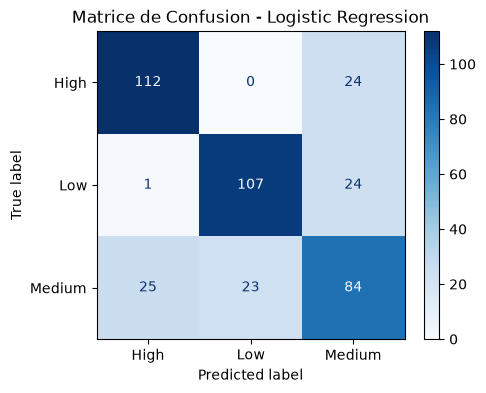

======== evaluation graphique : Random Forest========
ROC-AUC   : 0.8662


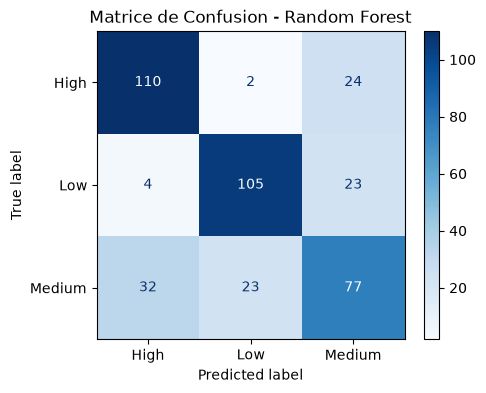

======== evaluation graphique : XGBoost========
ROC-AUC   : 0.8854


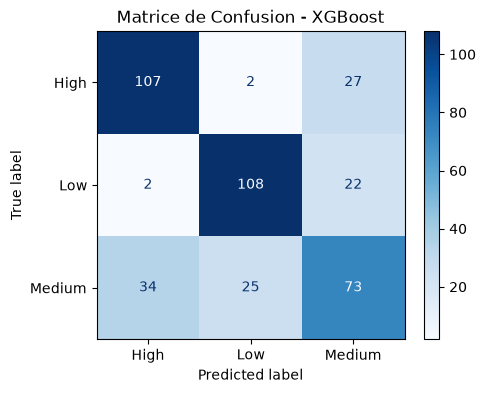

In [11]:
for nom_modele in modeles.keys():
    print(f"======== evaluation graphique : {nom_modele}========")
    
    
    y_pred = resultats_predictions[nom_modele]['y_pred']
    y_proba = resultats_predictions[nom_modele]['y_proba']
    
    try:
        roc_auc = roc_auc_score(y_test_encoded, y_proba, multi_class='ovr', average='weighted')
        print(f"ROC-AUC   : {roc_auc:.4f}")
    except Exception as e:
        print(f"ROC-AUC   : Non calculable ({e})")
        
    
    cm = confusion_matrix(y_test_encoded, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
    
    plt.figure(figsize=(5, 4))
    disp.plot(cmap=plt.cm.Blues, values_format='d', ax=plt.gca())
    plt.title(f"Matrice de Confusion - {nom_modele}")
    plt.show()